# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

Dataset: `amazon_reviews_lab.csv` (Amazon product reviews with a star rating, review text, summary and timestamp).

1. **Part 1 – NLP:** clean and preprocess review text, find frequent words and bigrams.
2. **Part 2 – Time series:** analyse review volume and ratings over time.
3. **Part 3 – Neural network:** predict the 1–5 star rating from review text with a TF-IDF + MLP model.

Place `amazon_reviews_lab.csv` in the same folder as this notebook.

## Part 1: NLP

In [1]:
import re, html
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.util import ngrams

# Download NLTK resources only if they are missing
for path, pkg in [("tokenizers/punkt", "punkt"), ("tokenizers/punkt_tab", "punkt_tab"),
                  ("corpora/stopwords", "stopwords"), ("corpora/wordnet", "wordnet")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(pkg, quiet=True)

sns.set_theme()

In [2]:
# Load the dataset
df = pd.read_csv("amazon_reviews_lab.csv")

print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("\nRating distribution:\n", df["rating"].value_counts().sort_index())
df.head()

Shape: (997, 9)

Missing values:
 product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

Rating distribution:
 rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


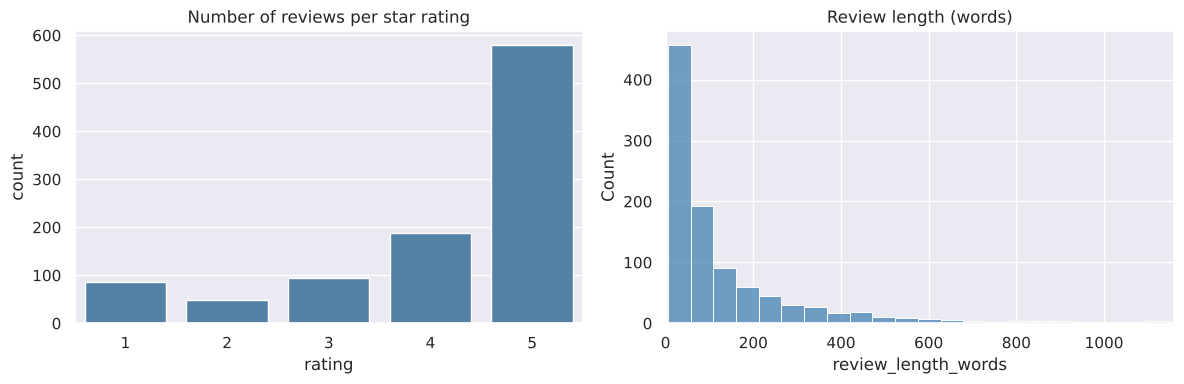

count     997.0
mean      146.4
std       216.1
min         5.0
25%        32.0
50%        67.0
75%       165.0
max      2079.0
Name: review_length_words, dtype: float64

Sentiment label counts:
 sentiment_label
positive    768
negative    135
neutral      94
Name: count, dtype: int64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="rating", data=df, ax=ax[0], color="steelblue")
ax[0].set_title("Number of reviews per star rating")
sns.histplot(df["review_length_words"], bins=40, ax=ax[1], color="steelblue")
ax[1].set_title("Review length (words)")
ax[1].set_xlim(0, df["review_length_words"].quantile(0.99))
plt.tight_layout(); plt.show()

print(df["review_length_words"].describe().round(1))
print("\nSentiment label counts:\n", df["sentiment_label"].value_counts())

**Observations.** The data is heavily skewed toward 5-star reviews, with only a few 2-star reviews.
This class imbalance matters for the neural network in Part 3. Reviews are short (most under ~150 words) but there is a long tail.

### Preprocessing tools and `preprocess_text`

In [4]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """lowercase -> unescape HTML -> remove URLs -> remove punctuation -> tokenize
    -> keep alphabetic tokens -> remove stopwords -> lemmatize -> return tokens"""
    text = html.unescape(str(text))                        # the raw data contains &quot; etc.
    text = text.lower()                                    # 1. lowercase
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)     # 2. remove URLs
    text = re.sub(r"<.*?>", " ", text)                     #    remove leftover HTML tags
    text = re.sub(r"[^\w\s]", " ", text)                  # 3. remove punctuation
    tokens = word_tokenize(text)                           # 4. tokenize
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]  # 5. alphabetic only; drops stray letters (n, b, u from "B&N", etc.)
    tokens = [t for t in tokens if t not in stop_words]    # 6. remove stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]     # 7. lemmatize
    tokens = [t for t in tokens if len(t) > 1]             #    lemmatizing "us" gives "u": drop stray letters again
    return tokens                                          # 8. cleaned tokens

example = df["review_text"].iloc[2]
print("RAW      :", example)
print("PROCESSED:", preprocess_text(example))

RAW      : I would love to buy this movie as I have been to Hannibal Missouri and been to all the Mark Twain atractions.To buy this movie would be a real treat but if it's Pan&Scan forget it! I dont buy full screen movies! Unless it's made for TV.I think MGM should of included a widescreen version of the movie.What a joke!


PROCESSED: ['would', 'love', 'buy', 'movie', 'hannibal', 'missouri', 'mark', 'twain', 'atractions', 'buy', 'movie', 'would', 'real', 'treat', 'pan', 'scan', 'forget', 'dont', 'buy', 'full', 'screen', 'movie', 'unless', 'made', 'tv', 'think', 'mgm', 'included', 'widescreen', 'version', 'movie', 'joke']


In [5]:
df["processed_tokens"] = df["review_text"].apply(preprocess_text)
df["n_tokens"] = df["processed_tokens"].apply(len)

# Validation of the preprocessing
raw_vocab = set(w for t in df["review_text"] for w in re.findall(r"[a-z]+", html.unescape(t.lower())))
clean_vocab = set(w for toks in df["processed_tokens"] for w in toks)
print(f"Vocabulary before: {len(raw_vocab):,}  ->  after: {len(clean_vocab):,} "
      f"({100*(1-len(clean_vocab)/len(raw_vocab)):.1f}% smaller)")
print("Empty reviews after cleaning:", (df["n_tokens"] == 0).sum())
print("Average tokens per review: ", round(df["n_tokens"].mean(), 1))

Vocabulary before: 7,529  ->  after: 6,547 (13.0% smaller)
Empty reviews after cleaning: 0
Average tokens per review:  71.3


### Word frequencies

[('nook', 1577), ('book', 986), ('one', 596), ('kindle', 590), ('screen', 535), ('like', 474), ('read', 464), ('work', 463), ('great', 444), ('tablet', 443), ('use', 432), ('tv', 427), ('get', 426), ('device', 399), ('would', 383), ('good', 348), ('reader', 346), ('well', 336), ('time', 329), ('also', 329)]


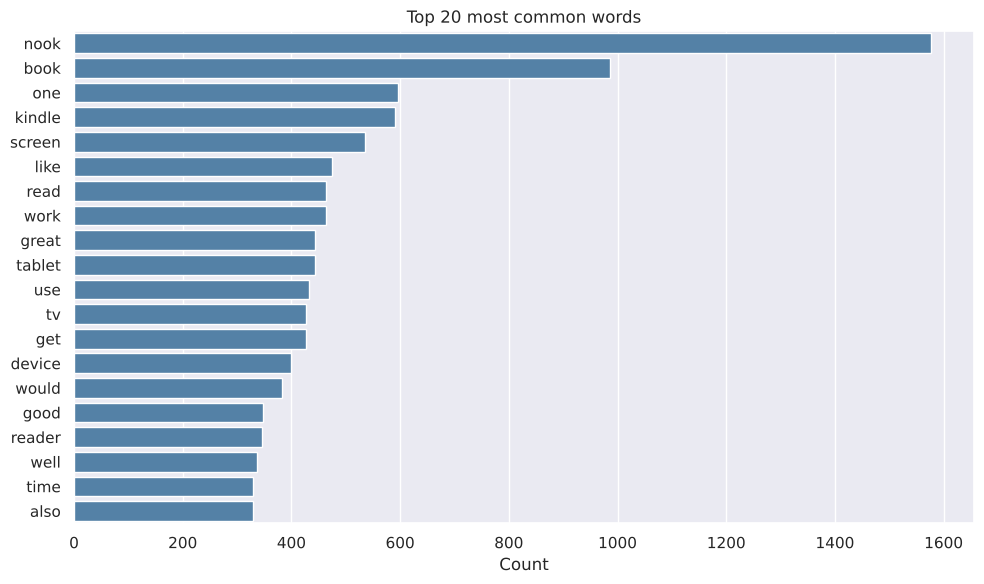

In [6]:
all_tokens = [t for toks in df["processed_tokens"] for t in toks]
word_counts = Counter(all_tokens)
top_words = word_counts.most_common(20)
print(top_words)

words, counts = zip(*top_words)
plt.figure(figsize=(10, 6))
sns.barplot(x=list(counts), y=list(words), color="steelblue")
plt.title("Top 20 most common words"); plt.xlabel("Count"); plt.tight_layout(); plt.show()

### Bigrams

[(('barnes', 'noble'), 166), (('nook', 'color'), 135), (('battery', 'life'), 98), (('touch', 'screen'), 96), (('sd', 'card'), 89), (('nook', 'hd'), 80), (('work', 'great'), 65), (('nook', 'tablet'), 64), (('kindle', 'fire'), 61), (('work', 'well'), 59), (('read', 'book'), 58), (('wall', 'mount'), 53), (('wi', 'fi'), 47), (('simple', 'touch'), 45), (('customer', 'service'), 41), (('android', 'tablet'), 41), (('micro', 'sd'), 39), (('original', 'nook'), 38), (('nook', 'kindle'), 37), (('nook', 'simple'), 37)]


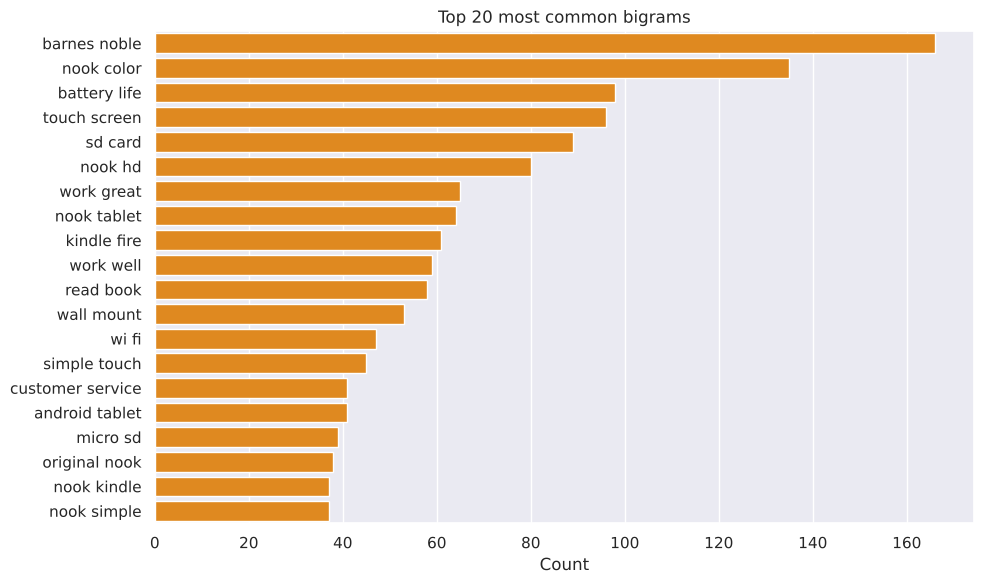

In [7]:
# bigrams are built within each review so no pair spans two reviews
bigram_counts = Counter(bg for toks in df["processed_tokens"] for bg in ngrams(toks, 2))
top_bigrams = bigram_counts.most_common(20)
print(top_bigrams)
labels = [" ".join(b) for b, _ in top_bigrams]
vals = [c for _, c in top_bigrams]

plt.figure(figsize=(10, 6))
sns.barplot(x=vals, y=labels, color="darkorange")
plt.title("Top 20 most common bigrams"); plt.xlabel("Count"); plt.tight_layout(); plt.show()

### Going further: language of positive vs. negative reviews

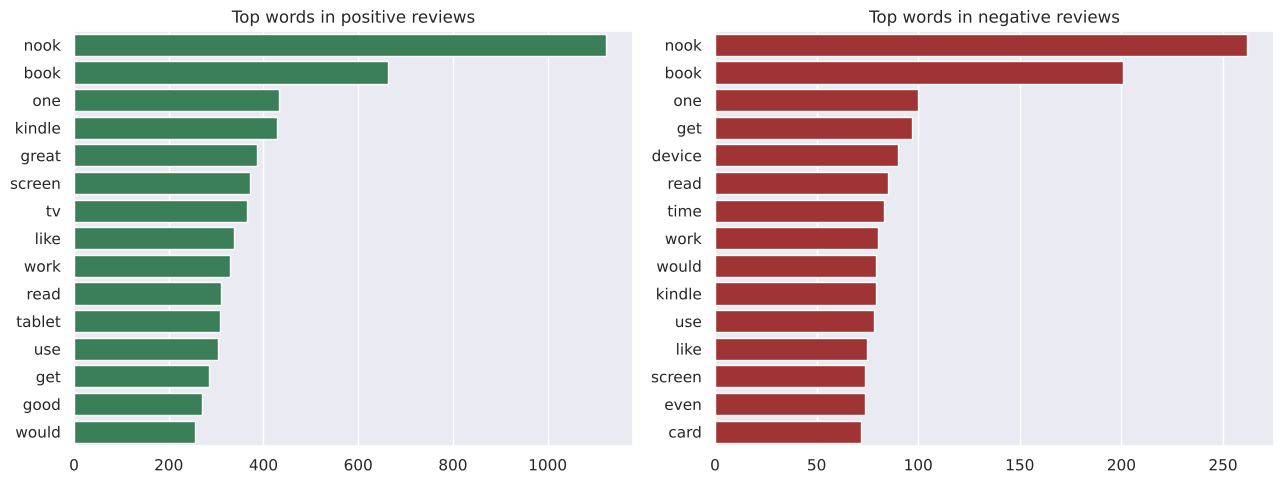

Most negative-skewed words: ['route', 'returning', 'credit', 'return', 'customer', 'fix', 'service', 'nothing', 'replacement', 'slow', 'limited', 'seller']


In [8]:
def top_terms(label, n=15):
    toks = [t for ts in df.loc[df["sentiment_label"] == label, "processed_tokens"] for t in ts]
    return Counter(toks).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (label, color) in zip(axes, [("positive", "seagreen"), ("negative", "firebrick")]):
    w, c = zip(*top_terms(label))
    sns.barplot(x=list(c), y=list(w), ax=ax, color=color)
    ax.set_title(f"Top words in {label} reviews")
plt.tight_layout(); plt.show()

# Words that over-index in negative reviews (relative frequency ratio, min count 15)
pos = Counter(t for ts in df.loc[df.sentiment_label == "positive", "processed_tokens"] for t in ts)
neg = Counter(t for ts in df.loc[df.sentiment_label == "negative", "processed_tokens"] for t in ts)
npos, nneg = sum(pos.values()), sum(neg.values())
ratio = {w: ((neg[w] / nneg) / ((pos[w] + 1) / npos)) for w in neg if neg[w] >= 15}
print("Most negative-skewed words:", sorted(ratio, key=ratio.get, reverse=True)[:12])

**Reflection (Part 1).** Reviews are overwhelmingly about e-readers and tablets: *nook*, *book*, *kindle*, *screen*, *tablet*, *device* and *reader* dominate the vocabulary, and the top bigrams are product names and features (*barnes noble*, *nook color*, *battery life*, *touch screen*, *sd card*, *wi fi*, *wall mount*). Customers mostly talk about hardware features rather than content. Sentiment words in the overall top 20 (*great*, *good*, *well*, *work*) are positive, which fits the 5-star skew (about 58% of reviews). The language of dissatisfaction is clearly different and is about **after-sales experience** rather than the product itself: *return/returning, replacement, credit, customer service, fix, slow, limited* are the words that over-index in negative reviews. For the support team this suggests routing posts containing return/refund/service vocabulary to the customer-care channel and posts about *sd card*, *battery* or *wi fi* to technical support. Limitations: lemmatizing without POS tags is imperfect, and stripping stopwords removes negations like *not*, which can matter for sentiment, so a different pipeline would be needed for a sentiment-focused model.

## Part 2: Time Series

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

df = pd.read_csv("amazon_reviews_lab.csv")

# Convert the timestamp column to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Earliest review:", df["timestamp"].min().date())
print("Latest review:  ", df["timestamp"].max().date())
print("Span (years):   ", round((df["timestamp"].max() - df["timestamp"].min()).days / 365.25, 1))

Earliest review: 2000-05-12
Latest review:   2014-07-17
Span (years):    14.2


In [10]:
ts = df.set_index("timestamp").sort_index()

monthly_review_count = ts["rating"].resample("MS").count()
monthly_avg_rating = ts["rating"].resample("MS").mean()   # NaN where a month has no reviews

print("Months covered:", len(monthly_review_count),
      "| months with at least one review:", (monthly_review_count > 0).sum())
monthly_review_count.describe()

Months covered: 171 | months with at least one review: 68


count    171.000000
mean       5.830409
std        9.943985
min        0.000000
25%        0.000000
50%        0.000000
75%       10.000000
max       46.000000
Name: rating, dtype: float64

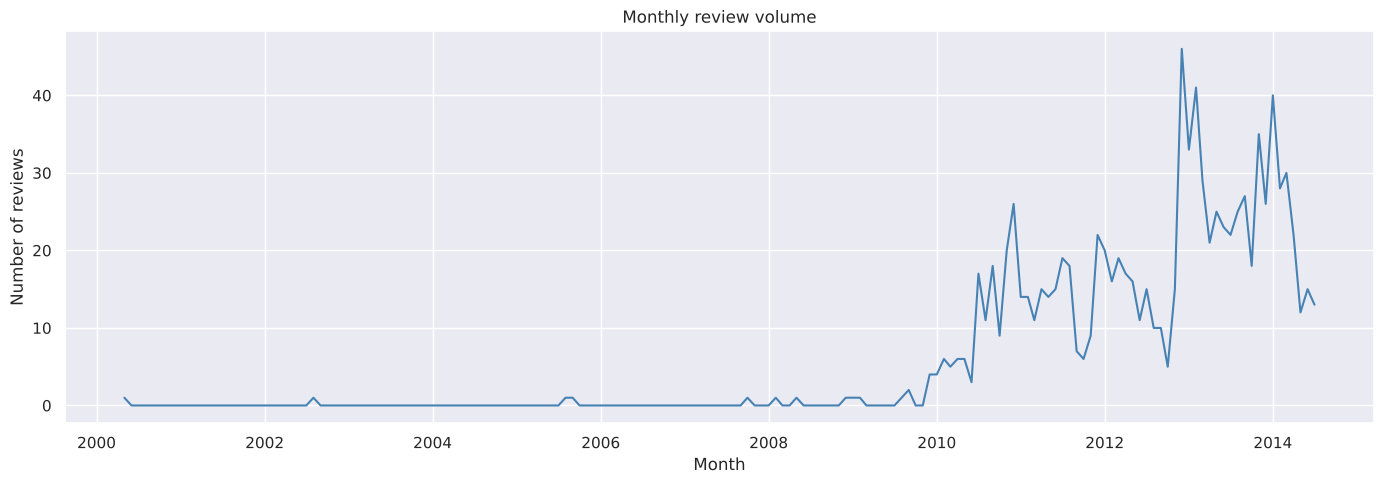

In [11]:
plt.figure(figsize=(14, 5))
plt.plot(monthly_review_count.index, monthly_review_count.values, color="steelblue")
plt.title("Monthly review volume"); plt.xlabel("Month"); plt.ylabel("Number of reviews")
plt.tight_layout(); plt.show()

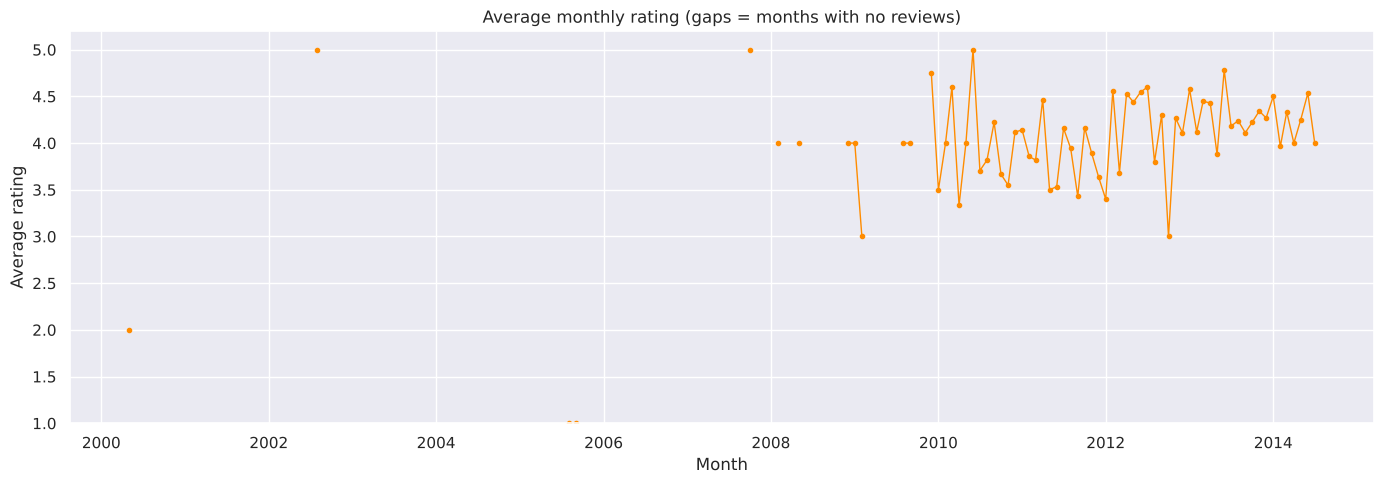

In [12]:
plt.figure(figsize=(14, 5))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, marker="o", ms=3, lw=1, color="darkorange")
plt.title("Average monthly rating (gaps = months with no reviews)")
plt.xlabel("Month"); plt.ylabel("Average rating"); plt.ylim(1, 5.2)
plt.tight_layout(); plt.show()

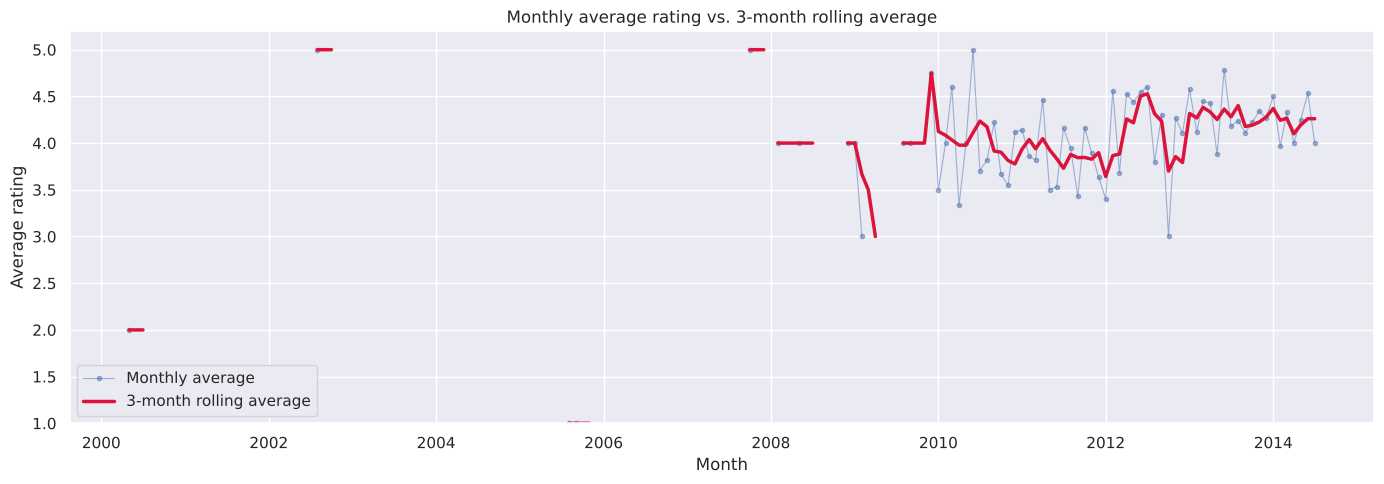

In [13]:
# 3-month rolling average. min_periods=1 lets the window work across the many sparse months;
# months with no reviews are ignored rather than counted as zero.
rolling_avg_rating = monthly_avg_rating.rolling(window=3, min_periods=1).mean()

plt.figure(figsize=(14, 5))
plt.plot(monthly_avg_rating.index, monthly_avg_rating, marker="o", ms=3, lw=0.8, alpha=0.5, label="Monthly average")
plt.plot(rolling_avg_rating.index, rolling_avg_rating, lw=2.5, color="crimson", label="3-month rolling average")
plt.title("Monthly average rating vs. 3-month rolling average")
plt.xlabel("Month"); plt.ylabel("Average rating"); plt.ylim(1, 5.2); plt.legend()
plt.tight_layout(); plt.show()

### Going further: yearly view and stationarity check

,count,mean
timestamp,,
2000,1,2.00
2001,0,NaN
2002,1,5.00
2003,0,NaN
2004,0,NaN
2005,2,1.00
2006,0,NaN
2007,1,5.00
2008,3,4.00


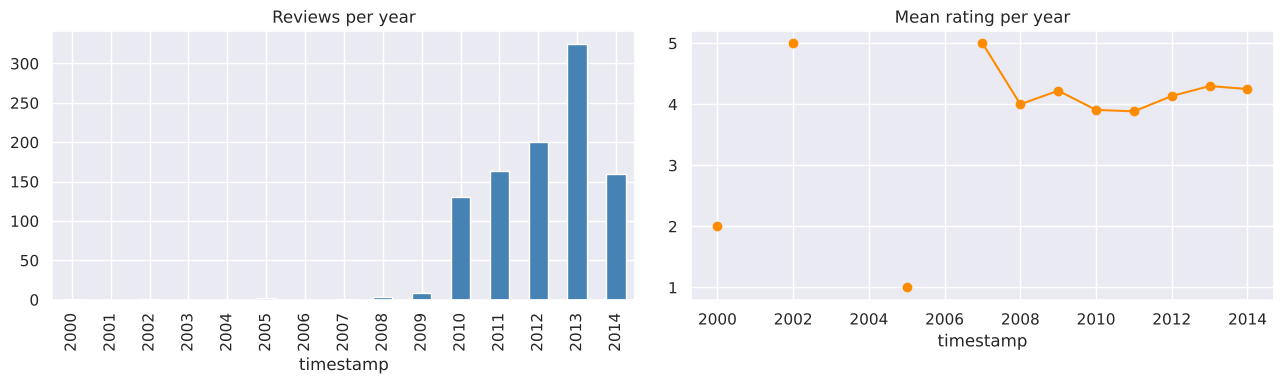

ADF statistic = -0.400, p-value = 0.9100
Critical values: {'1%': np.float64(-3.473), '5%': np.float64(-2.88), '10%': np.float64(-2.577)}
=> cannot reject non-stationarity at 5% (volume has a trend)


In [14]:
import warnings; warnings.filterwarnings("ignore")
from statsmodels.tsa.stattools import adfuller

yearly = ts["rating"].resample("YS").agg(["count", "mean"])
yearly.index = yearly.index.year
display(yearly.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
yearly["count"].plot.bar(ax=ax[0], color="steelblue", title="Reviews per year")
yearly["mean"].plot(marker="o", ax=ax[1], color="darkorange", title="Mean rating per year")
plt.tight_layout(); plt.show()

# ADF test on monthly volume (H0: series has a unit root, i.e. is non-stationary)
adf = adfuller(monthly_review_count.values)
print(f"ADF statistic = {adf[0]:.3f}, p-value = {adf[1]:.4f}")
print("Critical values:", {k: round(v, 3) for k, v in adf[4].items()})
print("=> stationary at 5%" if adf[1] < 0.05 else "=> cannot reject non-stationarity at 5% (volume has a trend)")

**Reflection (Part 2).** Activity is extremely uneven: only about 17 reviews fall between 2000 and 2009, then volume jumps to 131 in 2010 and peaks at 325 in 2013 (2014 is a partial year, ending in July). 103 of the 171 months have no reviews at all, so the monthly series is sparse and the early months of the average rating are based on one or two reviews and should not be over-interpreted. The ADF test on monthly volume gives p ≈ 0.91, so the series is **non-stationary** (it trends upward); differencing would be needed before fitting an ARIMA-type model. From 2010 onward the average rating is fairly stable between about 3.9 and 4.3: it dips slightly in 2010-2011 (≈3.9), then recovers to ≈4.3 in 2013-2014. The 3-month rolling average smooths the noisy month-to-month swings and makes this gentle recovery easier to see. Overall customers are generally satisfied, and the rise in review volume is consistent with growing sales or review activity for these devices.

## Part 3: Neural Networks

In [15]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)   # seeds python, numpy and tensorflow
sns.set_theme()

I0000 00:00:1792861488.722224    1126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792861490.585888    1126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [16]:
df = pd.read_csv("amazon_reviews_lab.csv")

X = df["review_text"].astype(str)
y = df["rating"] - 1            # ratings 1-5  ->  classes 0-4 (required by sparse/one-hot targets)
print(y.value_counts().sort_index())

rating
0     87
1     48
2     94
3    188
4    580
Name: count, dtype: int64


In [17]:
# TF-IDF: keep the 5,000 most informative unigrams+bigrams (reviews are short, so more features add mostly noise)
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# Split FIRST, then fit the vectorizer on the training text only (avoids leaking test vocabulary / IDF)
X_train_txt, X_test_txt, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train = vectorizer.fit_transform(X_train_txt).toarray().astype("float32")
X_test  = vectorizer.transform(X_test_txt).toarray().astype("float32")

# One-hot encode the targets
y_train_oh = keras.utils.to_categorical(y_train, num_classes=5)
y_test_oh  = keras.utils.to_categorical(y_test, num_classes=5)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (797, 5000)  Test: (200, 5000)


In [18]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax"),     # one probability per star rating
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,709 (2.47 MB)

 Trainable params: 648,709 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Class weights counteract the dominance of 5-star reviews
cw = compute_class_weight("balanced", classes=np.arange(5), y=y_train)
class_weight = dict(enumerate(cw)); print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
history = model.fit(X_train, y_train_oh, validation_split=0.2, epochs=40, batch_size=32,
                    class_weight=class_weight, callbacks=[early_stop], verbose=2)

Class weights: {0: np.float64(2.28), 1: np.float64(4.19), 2: np.float64(2.13), 3: np.float64(1.06), 4: np.float64(0.34)}


Epoch 1/40


20/20 - 1s - 64ms/step - accuracy: 0.3297 - loss: 1.6028 - val_accuracy: 0.5250 - val_loss: 1.5996


Epoch 2/40


20/20 - 0s - 9ms/step - accuracy: 0.5463 - loss: 1.5758 - val_accuracy: 0.5437 - val_loss: 1.5838


...

20/20 - 0s - 10ms/step - accuracy: 0.9906 - loss: 0.1172 - val_accuracy: 0.5562 - val_loss: 1.2870


Epoch 12/40


20/20 - 0s - 8ms/step - accuracy: 0.9969 - loss: 0.0855 - val_accuracy: 0.5312 - val_loss: 1.3199


Epoch 13/40


20/20 - 0s - 10ms/step - accuracy: 0.9922 - loss: 0.0788 - val_accuracy: 0.5250 - val_loss: 1.3580


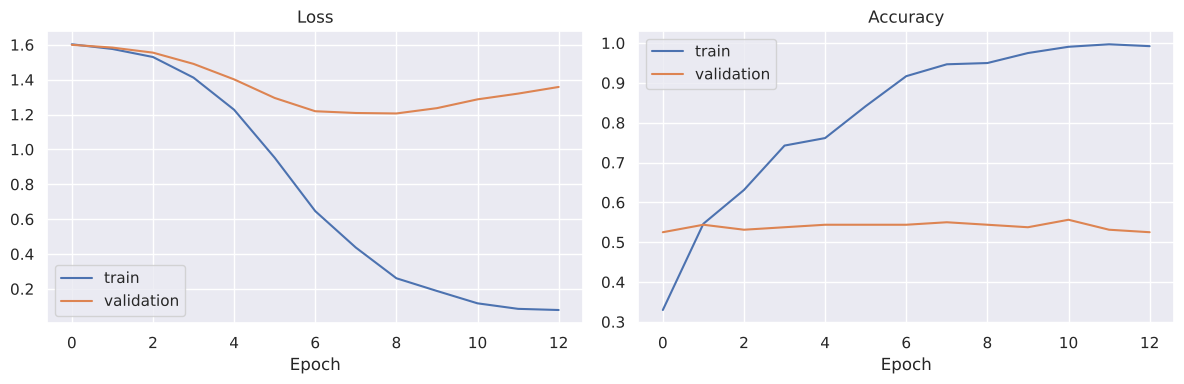

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Test loss: 1.259 | Test accuracy: 0.535
Baseline (always predict 5 stars): 0.580
              precision    recall  f1-score   support

      1 star       0.27      0.24      0.25        17
      2 star       0.00      0.00      0.00        10
      3 star       0.22      0.11      0.14        19
      4 star       0.35      0.18      0.24        38
      5 star       0.63      0.81      0.71       116

    accuracy                           0.54       200
   macro avg       0.29      0.27      0.27       200
weighted avg       0.47      0.54      0.49       200



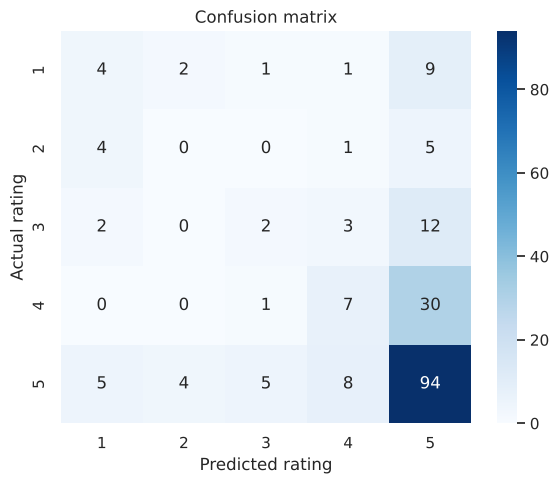

Predictions within +/-1 star of the truth: 0.775


In [21]:
test_loss, test_acc = model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Test loss: {test_loss:.3f} | Test accuracy: {test_acc:.3f}")
print(f"Baseline (always predict 5 stars): {(y_test == 4).mean():.3f}")

y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

print(classification_report(y_test + 1, y_pred + 1, target_names=[f"{i} star" for i in range(1, 6)], zero_division=0))

cm = confusion_matrix(y_test + 1, y_pred + 1)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(1, 6), yticklabels=range(1, 6))
plt.xlabel("Predicted rating"); plt.ylabel("Actual rating"); plt.title("Confusion matrix")
plt.tight_layout(); plt.show()

within_one = (np.abs(y_pred - y_test.values) <= 1).mean()
print(f"Predictions within +/-1 star of the truth: {within_one:.3f}")

### Going further: does the neural network beat a simple linear model?
A multinomial logistic regression on the same TF-IDF features is a sensible sanity check for a small dataset.

In [22]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print(f"Logistic regression accuracy: {accuracy_score(y_test, lr_pred):.3f} | "
      f"within +/-1 star: {(np.abs(lr_pred - y_test.values) <= 1).mean():.3f}")
print(f"Neural network accuracy:      {test_acc:.3f} | within +/-1 star: {within_one:.3f}")

Logistic regression accuracy: 0.580 | within +/-1 star: 0.815
Neural network accuracy:      0.535 | within +/-1 star: 0.775


**Reflection (Part 3).** The network (TF-IDF → 128 → 64 → 5 softmax, with dropout and class weights) reaches roughly 50-55% test accuracy (the exact figure shifts by a few points between runs because of random initialisation and the small test set of 200 reviews), which is **no better than always predicting 5 stars (58%)**; a logistic regression on the same features is about the same (58%), so on ~800 training reviews the extra capacity of the network does not pay off. The training curves show strong overfitting: training accuracy approaches 100% while validation loss stops improving after about 8 epochs (early stopping restores the best weights). The model is good at the dominant class (5 stars: F1 ≈ 0.7) and weak on the middle ratings 2-4 (F1 between 0 and about 0.25; the 2-star class is essentially never predicted), because 3 and 4 star reviews use mixed, moderate language that overlaps with both neighbours, and 2-star has only 48 examples overall. The errors are mostly adjacent ratings: about 78% of predictions are within one star. Ways to improve: more data or fewer classes (e.g. negative / neutral / positive), stronger regularisation, pre-trained embeddings or a fine-tuned transformer, and tuning the decision thresholds for the minority classes.